In [9]:
import sys; sys.path.insert(0, '../..')
from paths import CODE
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
sns.set()
# sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi

In [20]:
neural_root = '/home/wx2203/Weihao/data_locker/step_2/'
rotary_root = '/home/wx2203/RS_analysis/H_b_new/'
dlc_root = '/home/wx2203/RS_analysis/DLC/'
whisk_dlc_root = '/home/wx2203/Weihao/analysis/DLC/'
pupil_path = '/home/wx2203/RS_analysis/DLC/updated_pupil/pupil_128_07042020.mat'
groom_dlc_root = '/home/wx2203/Weihao/behavior_locker/body_dlc/'
config_root = '/home/wx2203/Weihao/data_locker/step_0/'
mirror_dlc_root = '/home/wx2203/Weihao/behavior_locker/mirror_dlc/'
stimframes_root = '/scratch/users/wx2203/H_new/'

# 1. STIM

In [15]:
# files without random stim

file_stim = list(set(glob.glob(neural_root+"*128/[4-7]/H_*[E-G]*.mat")) )
#           - set(glob.glob(neural_root+"*128/[5]/H_*B*.mat")))
# f3 = [f for f in glob.glob(neural_root + "*128/[4-7]/H_*[H-J]*.mat", recursive=True)]

file_stim

['/home/wx2203/Weihao/data_locker/step_2/cm128/7/H_runE_stim_1.mat',
 '/home/wx2203/Weihao/data_locker/step_2/cm128/5/H_runF_stim_1.mat',
 '/home/wx2203/Weihao/data_locker/step_2/cm128/6/H_runG_stim_1.mat',
 '/home/wx2203/Weihao/data_locker/step_2/cm128/6/H_runF_stim_1.mat',
 '/home/wx2203/Weihao/data_locker/step_2/cm128/7/H_runG_stim_1.mat',
 '/home/wx2203/Weihao/data_locker/step_2/cm128/4/H_runG_stim_1.mat',
 '/home/wx2203/Weihao/data_locker/step_2/cm128/4/H_runF_stim_1.mat',
 '/home/wx2203/Weihao/data_locker/step_2/cm128/5/H_runE_stim_1.mat',
 '/home/wx2203/Weihao/data_locker/step_2/cm128/5/H_runG_stim_1.mat',
 '/home/wx2203/Weihao/data_locker/step_2/cm128/7/H_runF_stim_1.mat',
 '/home/wx2203/Weihao/data_locker/step_2/cm128/4/H_runE_stim_1.mat',
 '/home/wx2203/Weihao/data_locker/step_2/cm128/6/H_runE_stim_1.mat']

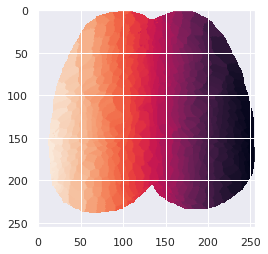

In [12]:
with h5py.File('/home/wx2203/Weihao/data_locker/step_0/idx_sorted_500_cm128.mat','r') as f_idx:

    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
plt.imshow(IDX_sorted)

In [13]:
def IsPointInROI(x1, y1, x2, y2, x, y) : 
    if (x > x1 and x < x2 and y > y1 and y < y2) : 
        return True
    else: 
        return False

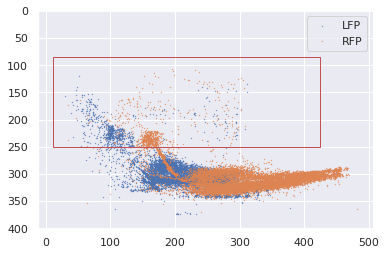

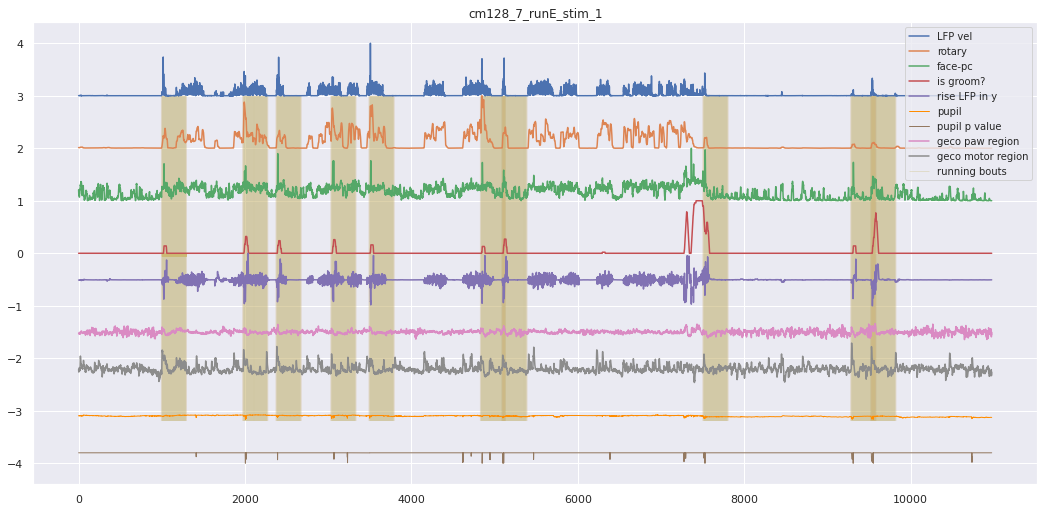

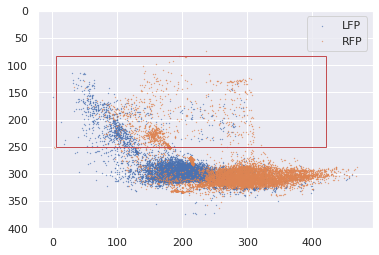

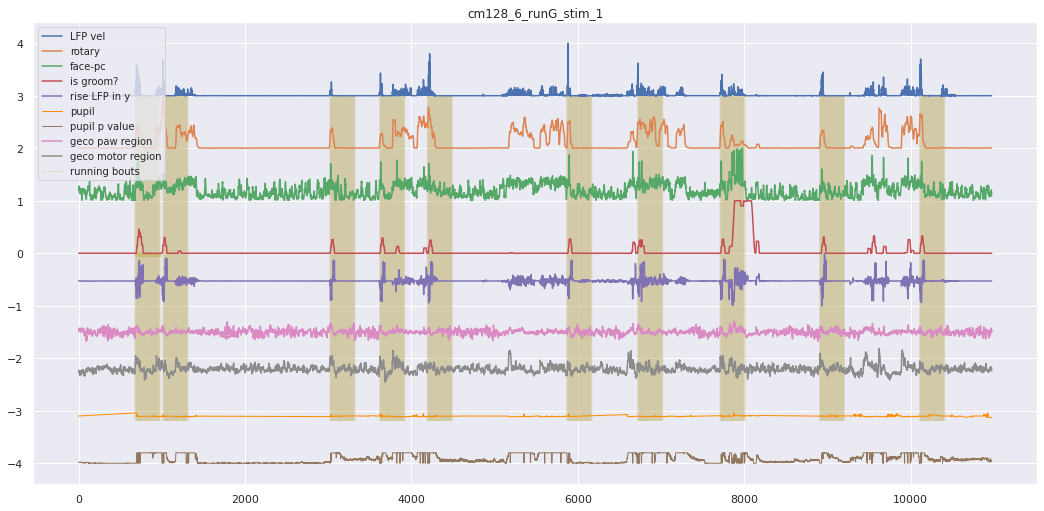

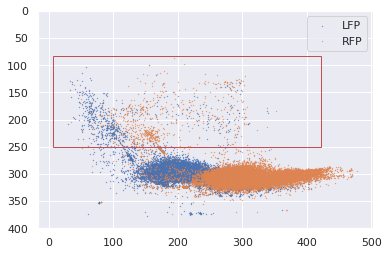

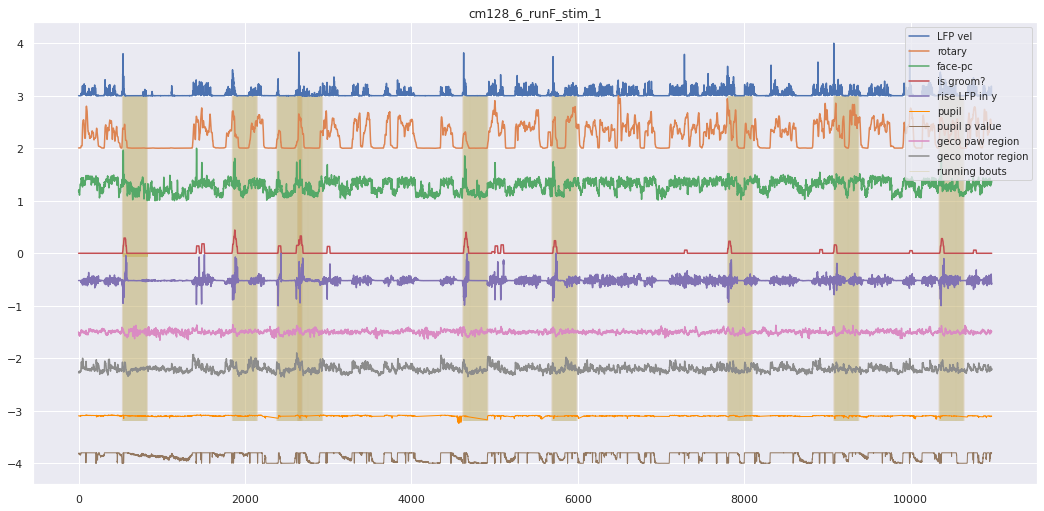

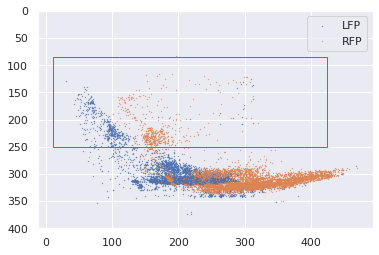

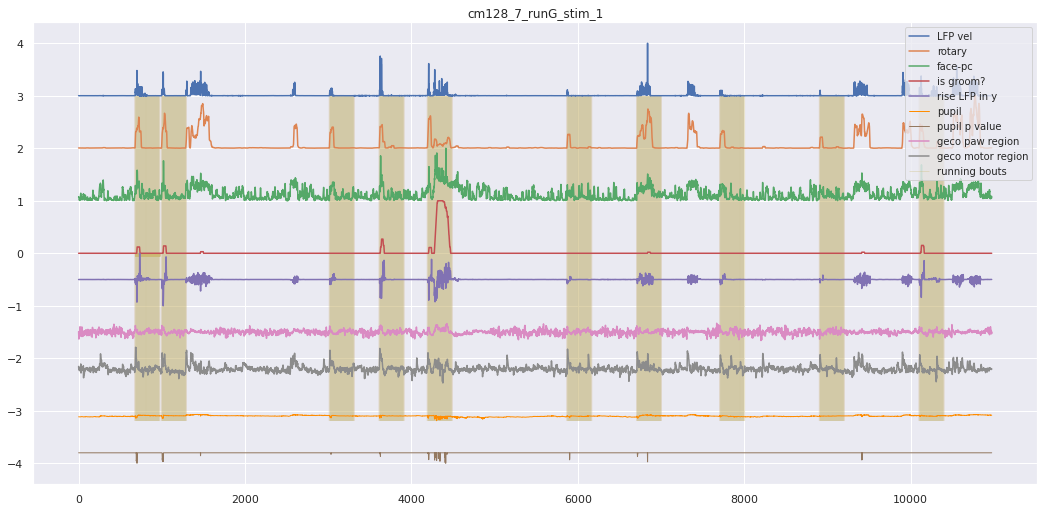

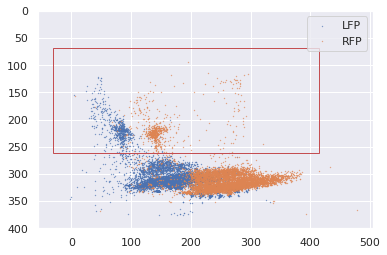

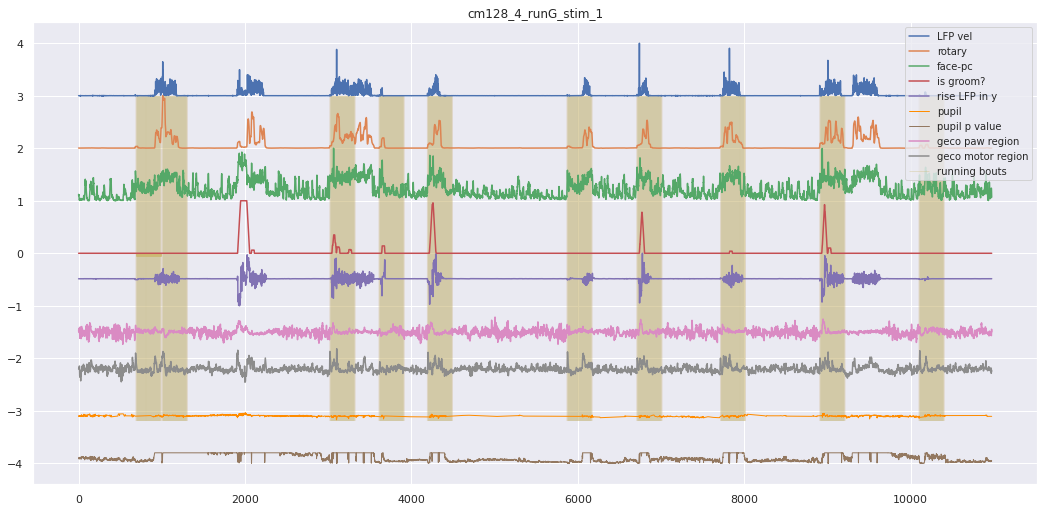

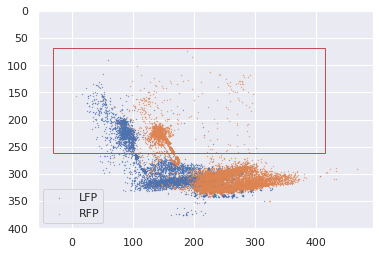

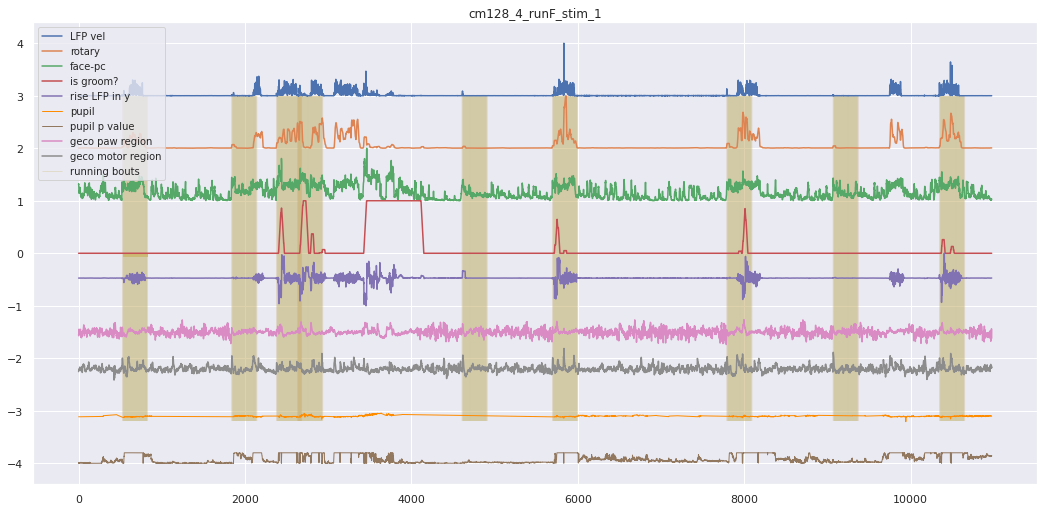

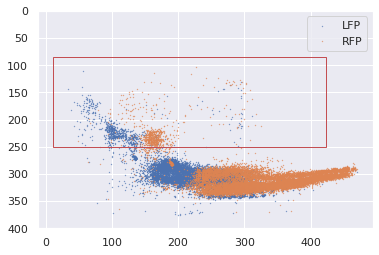

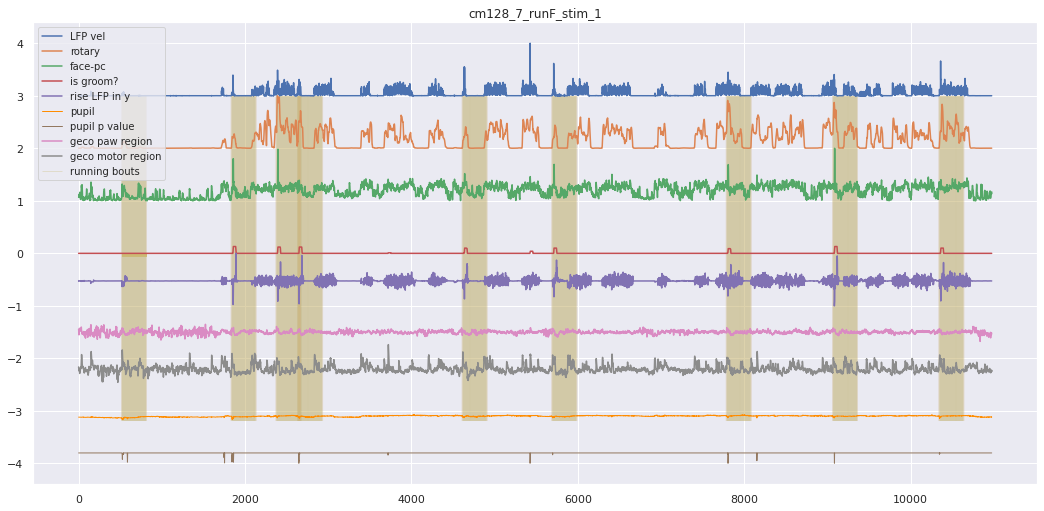

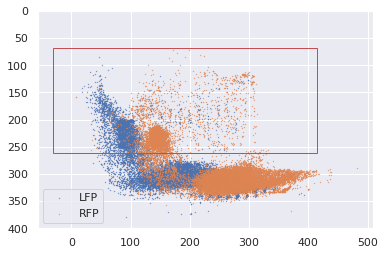

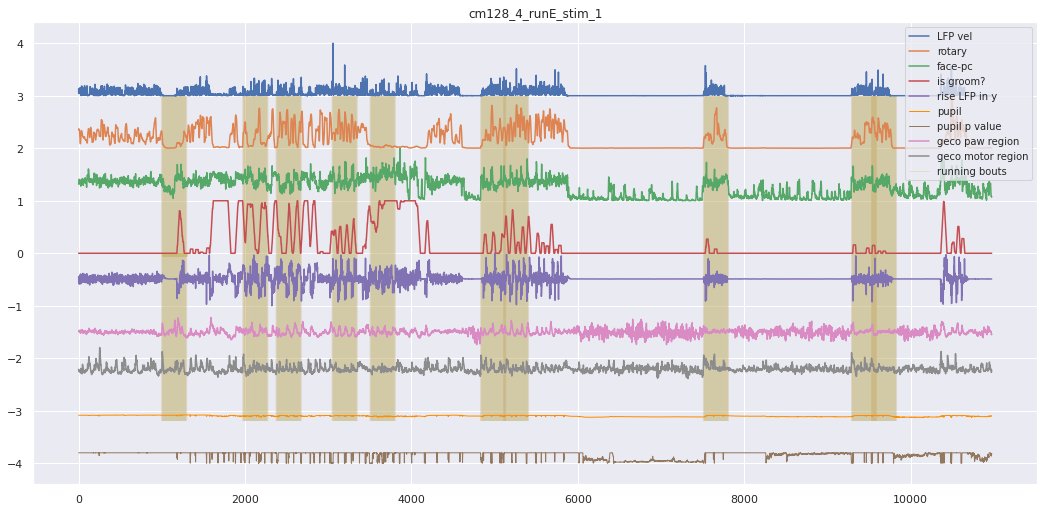

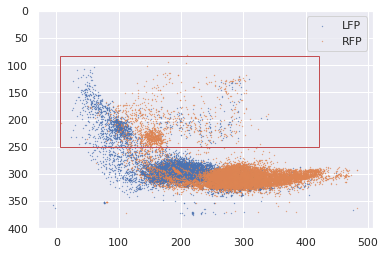

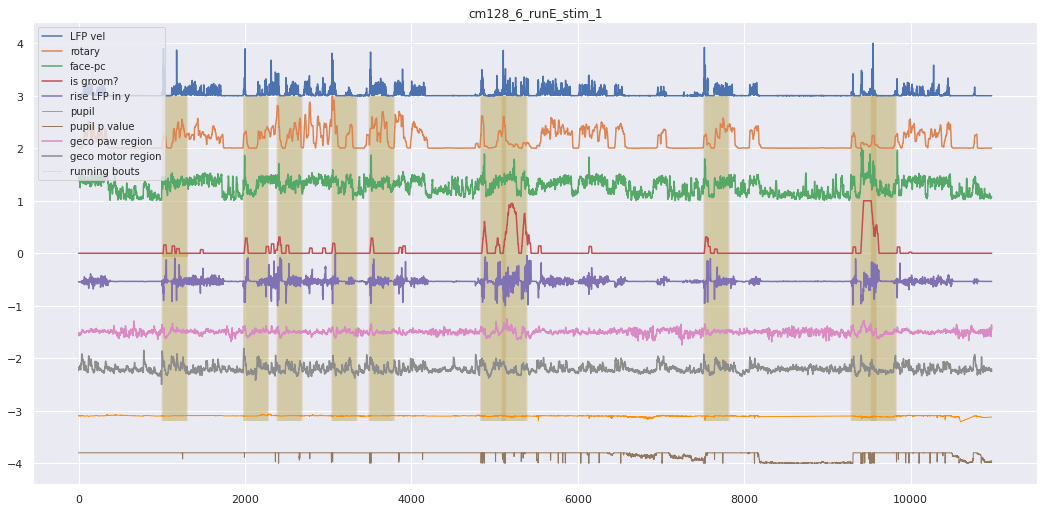

In [73]:
sns.set()
###################################################################### M setting
T = 500
T_PRE = 200
T_POST = 300
num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1)))) 

M_jrgeco = np.empty((num_regions,T,0))
M_jrgeco_std = np.empty((num_regions,T,0))
M_chbt = np.empty((num_regions,T,0))
M_chbt_std = np.empty((num_regions,T,0))
M_rotf = np.empty((T,0))
M_rotf_raw = np.empty((T,0))
M_pupil_pc = np.empty((T,0))
M_pupil_pc_norm = np.empty((T,0))
M_face_pc = np.empty((T,0))
M_body_pc = np.empty((T,0))
M_whisk_vel = np.empty((T,0))
M_whisk_vel_norm = np.empty((T,0))
M_nose_vel = np.empty((T,0))
M_nose_vel_norm = np.empty((T,0))
M_pupil_p_value = np.empty((T,0))
M_day_label = np.empty((0))
M_is_groom = np.empty((T,0))
M_ind_groom_onset = np.empty((0))
M_y_rise_LFP = np.empty((T,0))
M_y_rise_LFP_raw = np.empty((T,0))
M_LFP_vel = np.empty((T,0))
M_LFP_vel_norm = np.empty((T,0))
M_RFP_vel = np.empty((T,0))
M_RFP_vel_norm = np.empty((T,0))

M_mirrorRFP_vel = np.empty((T,0))
M_mirrorRFP_vel_norm = np.empty((T,0))
M_mirrorLFP_vel = np.empty((T,0))
M_mirrorLFP_vel_norm = np.empty((T,0))
M_mirrorRHP_vel = np.empty((T,0))
M_mirrorRHP_vel_norm = np.empty((T,0))
M_mirrorLHP_vel = np.empty((T,0))
M_mirrorLHP_vel_norm = np.empty((T,0))



for i_file,fname in enumerate(file_stim): 
    f = h5py.File(fname,'r')
    ################################### identity 
    run_name = fname[-15:-4]
    mouse = fname[-25:-20]
    day = fname[-19:-18]
    mouse_day = mouse+'_'+day
    run = fname[-15:-11]

    try:
        with h5py.File(pjoin(neural_root,mouse,day,'H_'+run+'_stim_1.mat'),'r') as f_H: 

            H = np.array(f_H['H']).transpose() #(36,11975)
            H_chbt = np.array(f_H['H_chbt']).transpose() #(36,11975)

            H_std = np.array(pd.DataFrame(H).rolling(window=20,axis=1).std())  
            H_chbt_std = np.array(pd.DataFrame(H_chbt).rolling(window=20,axis=1).std()) 

            H_std = H_std[:,500:-500]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming        
            H_chbt_std = H_chbt_std[:,500:-500]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming
            H = H[:,500:-500]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming
            H_chbt = H_chbt[:,500:-500]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming
    
    except:
        print('missing',mouse,day,'H_'+run+'_stim_1.mat')
        continue
        
    ################################### rotary (11980, 1)
    try:
        with h5py.File(rotary_root+mouse_day+'_'+run+'_H.mat','r') as f_rot:
            rotf = pd.DataFrame((f_rot['rotf'])).rolling(window=30,axis=0).std()
            rotf = rotf.iloc[500:-505]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming   

            rotf = stats.zscore(rotf)

            rotf_raw = stats.zscore(np.array(f_rot['rotf']))      
            rotf_raw = rotf_raw[500:-505]
            rotf_raw = stats.zscore(rotf_raw)        
            
    except:
        print('rotf or stimframes missing ',mouse_day+'_'+run,' but use body PC instead')
        # No rotf file found? Use body_pc instead..
        rotf = body_pc.copy()
        rotf_raw = rotf  
        continue
        
        
    # load pupil 
    try:
        x = scipy.io.loadmat(pupil_path)
        pupil = np.empty((35941,0))
        pupil_p = np.empty((35941,0))
        for key in ['Top']+['TopR']+['Right']+['BottomR']+['Bottom']+['BottomL']+['Left']+['TopL']+['Eyelid']:
            pupil = np.append(pupil,x[mouse_day+'_'+run][key][0,0][:,:2],axis=1)
            pupil_p = np.append(pupil_p,x[mouse_day+'_'+run][key][0,0][:,2:3],axis=1)

        pupil_p_value = np.mean(pupil_p,axis=1)

        pca = PCA(n_components=1)
        pupil_pc = pca.fit_transform(pupil)  
        df = pd.DataFrame(pupil_pc).copy()
        df.iloc[pupil_p_value < 0.5]=np.nan


        pupil_pc = np.array(df.interpolate())
        pupil_pc = np.mean(pupil_pc[:-1].reshape((-1,3)),axis=1)
        pupil_pc = -pupil_pc[500:-505]
        pupil_pc = stats.zscore(pupil_pc)
        pupil_p_value = np.mean(pupil_p_value[:-1].reshape((-1,3)),axis=1)
        pupil_p_value = pupil_p_value[500:-505]

    except:
        print('pupil missing ',mouse_day+'_'+run)
        continue
    
    
    ################################### whisking velocity (11980,)
    try:
        f_name_dlc = glob.glob(whisk_dlc_root+'face/' + mouse_day+'_'+run+"*h5", recursive=True)[0] # target at specific run
        Dataframe = pd.read_hdf(f_name_dlc)
        scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
        new_df = Dataframe[scorer] # de-level
        bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()
        prominent_whiskers=bodyparts[7:] #plot most prominent whiskers

        vel_df = pd.DataFrame()
        for i_bpt,bpt in enumerate(prominent_whiskers):
            vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
            vel_df[bpt] = vel
        mean_vel = vel_df.mean(axis=1)
        smooth_mean_vel = mean_vel.rolling(15).std()
        smooth_mean_vel_ds = np.mean(smooth_mean_vel[:-1].values.reshape((-1,3)),axis=1) #(11980,)
        whisk_vel = smooth_mean_vel_ds[500:-505]
        #
        nose_pts=bodyparts[:7]
        nose_vel_df = pd.DataFrame()
        for i_bpt,bpt in enumerate(nose_pts):
            vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
            nose_vel_df[bpt] = vel
        mean_nose_vel = nose_vel_df.mean(axis=1)
        smooth_mean_nose_vel = mean_nose_vel.rolling(15).std() # smooth
        smooth_mean_nose_vel_ds = np.mean(smooth_mean_nose_vel[:-1].values.reshape((-1,3)),axis=1)
        nose_vel = smooth_mean_nose_vel_ds[500:-505]

    except:
        print('whisking velocity missing ',mouse_day+'_'+run)
        continue
        
    try:
        with(h5py.File(pjoin('/home/wx2203/RS_analysis/behavior',
                             mouse,day,run+'_cam_pc.mat'),'r')) as f_b:
            motionS = f_b['motionS']# this is the HDF5 reference
            motion_pc = {key: [] for key in list(motionS.keys())} 
            for key in list(motionS.keys()):
                motion_pc[key] = pd.DataFrame(motionS[key]).transpose()# this is the actual data
                motion_pc[key]= motion_pc[key].iloc[:,:-5]
                
                motion_pc[key] = motion_pc[key].rolling(window=5,axis=1).std()
                motion_pc[key]=motion_pc[key].iloc[:,500:-500]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming

    except:
        continue

    try:    
        f_config = h5py.File(config_root+'groom_config_'+mouse+'.mat','r')

        x_top_left = np.array(f_config[f_config['xx']['face'][int(day)-1,0]])[:,0]
        x_botton_right = np.array(f_config[f_config['xx']['face'][int(day)-1,0]])[:,1]
        y_top_left = np.array(f_config[f_config['yy']['face'][int(day)-1,0]])[:,0]
        y_botton_right = np.array(f_config[f_config['yy']['face'][int(day)-1,0]])[:,1]

        out_h = int((x_botton_right - x_top_left)/3)
        out_w = int((y_botton_right - y_top_left)/3) +200
        y = int(x_top_left/3)
        x = int(y_top_left/3)-50 # wider

        f_name_dlc = glob.glob(groom_dlc_root +mouse+'/'+ mouse_day+'_'+run+"*h5", recursive=True)[0] # target at specific run
        Dataframe = pd.read_hdf(f_name_dlc)
        scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
        new_df = Dataframe[scorer] # de-level

        paws_vel_df = pd.DataFrame()
        bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()
        for i_bpt,bpt in enumerate(bodyparts):
            vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
            vel = pd.DataFrame(vel)#.rolling(15).std()
            vel = np.mean(vel[:-1].values.reshape((-1,3)),axis=1)
            paws_vel_df[bpt] = vel[500:-505]
        LFP_vel = np.array(paws_vel_df['LFP'])
        RFP_vel = np.array(paws_vel_df['RFP'])
        
        
        fig,ax = plt.subplots(1)
        plt.scatter(new_df['LFP']['x'],new_df['LFP']['y'],s=0.1,label='LFP')
        plt.scatter(new_df['RFP']['x'],new_df['RFP']['y'],s=0.1,label='RFP')
        rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='r',facecolor='none')
        plt.ylim([0,400])
        plt.legend()
        ax.add_patch(rect)
        plt.gca().invert_yaxis()

        rise_LFP = new_df['LFP']['y'].copy().diff().rolling(100).mean()
        rise_LFP = np.mean(rise_LFP[:-1].values.reshape((-1,3)),axis=1) #(11980,)
        rise_LFP = normalize(stats.zscore(rise_LFP[500:-505]))

        rise_LFP_raw = new_df['LFP']['y'].copy().diff()
        rise_LFP_raw = np.mean(rise_LFP_raw[:-1].values.reshape((-1,3)),axis=1) #(11980,)
        rise_LFP_raw = rise_LFP_raw[500:-505]   

        is_groom_LFP = new_df.apply(lambda row: IsPointInROI(x, y, x+out_w, y+out_h,row['LFP']['x'], row['LFP']['y']), axis=1)
        is_groom_RFP = new_df.apply(lambda row: IsPointInROI(x, y, x+out_w, y+out_h,row['RFP']['x'], row['RFP']['y']), axis=1)
        is_groom = np.logical_or(is_groom_LFP,is_groom_RFP)
        is_groom_smooth = is_groom.rolling(100).mean()

        is_groom_smooth_ds = np.mean(is_groom_smooth[:-1].values.reshape((-1,3)),axis=1) #(11980,)
        is_groom_smooth_ds = is_groom_smooth_ds[500:-505]

    except:
        print('grooming missing ',mouse_day+'_'+run)   
        continue
        
    try:
        paws_vel_df = pd.DataFrame()
        f_name_dlc = glob.glob(mirror_dlc_root + mouse_day[2:]+'_'+run+"*h5", recursive=True)[0] # target at specific run
        Dataframe = pd.read_hdf(f_name_dlc)
        scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
        new_df = Dataframe[scorer] # de-level
    #     bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()
        bodyparts=['LFP','RFP','LHP','RHP']
        for i_bpt,bpt in enumerate(bodyparts):
            vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
            vel = pd.DataFrame(vel)#.rolling(15).std()
            vel = np.mean(vel[:-1].values.reshape((-1,3)),axis=1)
            paws_vel_df[bpt] = vel[500:-505]
        mirrorLFP_vel = np.array(paws_vel_df['LFP'])
        mirrorRFP_vel = np.array(paws_vel_df['RFP'])
        mirrorLHP_vel = np.array(paws_vel_df['LHP'])
        mirrorRHP_vel = np.array(paws_vel_df['RHP'])
    except:
        print('mirror paws velocity missing ',mouse_day+'_'+run)
        continue        
        

    
    
    face_pc = motion_pc['face'].iloc[:200,:].mean(axis=0)
    face_pc = stats.zscore(face_pc)
    body_pc = motion_pc['body'].iloc[:200,:].mean(axis=0)
    body_pc = stats.zscore(body_pc)    
    whisk_vel_norm = stats.zscore(whisk_vel)
    nose_vel_norm = stats.zscore(nose_vel)
    pupil_pc_norm = stats.zscore(pupil_pc)
    LFP_vel_norm = stats.zscore(LFP_vel)
    RFP_vel_norm = stats.zscore(RFP_vel)    
    mirrorLFP_vel_norm = stats.zscore(mirrorLFP_vel)
    mirrorRFP_vel_norm = stats.zscore(mirrorRFP_vel)
    mirrorLHP_vel_norm = stats.zscore(mirrorLHP_vel)
    mirrorRHP_vel_norm = stats.zscore(mirrorRHP_vel)
        
       
    # getting stim frames
    try:
        f = scipy.io.loadmat(stimframes_root+mouse_day+'_'+run+'_H.mat')
        m = f['m']
        stimframes = np.squeeze(m['stimframes'][0,0])
        stimframes = stimframes -500
        stimframes = stimframes[stimframes>0] 
        stimframes = stimframes[stimframes<10375]
    except:
        print('stimframes bug ',mouse,day,'H_'+run+'_stim_1.mat')
        continue

    ################### plotting stuffs + ***[start_stop_ind]***
    start_stop_ind = pd.DataFrame(np.stack((stimframes,stimframes+T_POST)).T)


    is_groom_start_stop = start_stop(np.squeeze(is_groom_smooth_ds>0.1),trigger_val = True)
    
#     temp = []
#     for i in range(len(start_stop_ind)):
#         x1 = start_stop_ind.iloc[i,0];x2 = start_stop_ind.iloc[i,1];
#         temp.append(any(max(x1,lower) <= min(x2,upper) for (lower, upper) in list(is_groom_start_stop)))
#     start_stop_ind['is_in_groom']=temp
#     start_stop_ind = start_stop_ind[start_stop_ind['is_in_groom']==False]

        
    try:
        plt.figure(figsize=(18,8.5))
        plt.plot(normalize(LFP_vel_norm)+3,label='LFP vel')
        plt.plot(normalize(rotf)+2,label='rotary')
        plt.plot(normalize(face_pc)+1,label='face-pc')
        plt.plot(is_groom_smooth_ds,label='is groom?')
        plt.plot(rise_LFP-1,label='rise LFP in y')
        for i in range(len(start_stop_ind)):
            plt.vlines(range(start_stop_ind.iloc[i,0],start_stop_ind.iloc[i,1]),
                       -3.2, 3,linewidth = 0.2,color='y',alpha=0.3)
        plt.vlines(range(start_stop_ind.iloc[0,0],start_stop_ind.iloc[0,1]),
                       -0.05, 0.01,linewidth = 1,color='y',alpha=0.3,label='running bouts')

        plt.title(mouse_day+'_'+run_name)
        plt.plot(pupil_pc/80-3.1,color='darkorange',alpha=1,linewidth=1,label='pupil')
        plt.plot(pupil_p_value/5-4,alpha=1,linewidth=1,label='pupil p value')
        plt.plot(H[134,:]*3-1.5,label='geco paw region')
        plt.plot(H[73,:]*3-2.2,label='geco motor region')
        plt.legend(fontsize = 10)
    except:
        print('no start_stop_ind')
        continue

    for i in range(len(start_stop_ind)):
        M_jrgeco = np.append(M_jrgeco,H[:,start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((num_regions,T,1)),axis=2)
        M_jrgeco_std = np.append(M_jrgeco_std,H_std[:,start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((num_regions,T,1)),axis=2)
        M_chbt = np.append(M_chbt,H_chbt[:,start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((num_regions,T,1)),axis=2)
        M_chbt_std = np.append(M_chbt_std,H_chbt_std[:,start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((num_regions,T,1)),axis=2)

        M_rotf_raw = np.append(M_rotf_raw,rotf_raw[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_rotf = np.append(M_rotf,rotf[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_pupil_pc = np.append(M_pupil_pc,pupil_pc[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_face_pc = np.append(M_face_pc,face_pc[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_body_pc = np.append(M_body_pc,body_pc[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_whisk_vel = np.append(M_whisk_vel,whisk_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_whisk_vel_norm = np.append(M_whisk_vel_norm,whisk_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_nose_vel = np.append(M_nose_vel,nose_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_nose_vel_norm = np.append(M_nose_vel_norm,nose_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_LFP_vel = np.append(M_LFP_vel,LFP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_LFP_vel_norm = np.append(M_LFP_vel_norm,LFP_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_RFP_vel = np.append(M_RFP_vel,RFP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_RFP_vel_norm = np.append(M_RFP_vel_norm,RFP_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_pupil_pc_norm = np.append(M_pupil_pc_norm,pupil_pc_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)        
                        
        M_pupil_p_value = np.append(M_pupil_p_value,pupil_p_value[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)


    
        M_mirrorLFP_vel = np.append(M_mirrorLFP_vel,mirrorLFP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorLFP_vel_norm = np.append(M_mirrorLFP_vel_norm,mirrorLFP_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorRFP_vel = np.append(M_mirrorRFP_vel,mirrorRFP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorRFP_vel_norm = np.append(M_mirrorRFP_vel_norm,mirrorRFP_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorLHP_vel = np.append(M_mirrorLHP_vel,mirrorLHP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorLHP_vel_norm = np.append(M_mirrorLHP_vel_norm,mirrorLHP_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorRHP_vel = np.append(M_mirrorRHP_vel,mirrorRHP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorRHP_vel_norm = np.append(M_mirrorRHP_vel_norm,mirrorRHP_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)


        M_is_groom = np.append(M_is_groom,is_groom_smooth_ds[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_ind_groom_onset = np.append(M_ind_groom_onset,start_stop_ind.iloc[i,0]+500)
        M_day_label = np.append(M_day_label,mouse_day+'_'+run)
        M_y_rise_LFP = np.append(M_y_rise_LFP,rise_LFP[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_y_rise_LFP_raw = np.append(M_y_rise_LFP_raw,rise_LFP_raw[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)

      

In [74]:
# scipy.io.savemat('/home/wx2203/Weihao/analysis_locker/f2stim/'+mouse+'_raw.mat',
#                        {'M_jrgeco':M_jrgeco,
#                         'M_jrgeco_std':M_jrgeco_std,
#                         'M_chbt':M_chbt,
#                         'M_chbt_std':M_chbt_std,
#                         'M_rotf':M_rotf,
#                         'M_rotf_raw':M_rotf_raw,
#                         'M_face_pc':M_face_pc,
#                         'M_body_pc':M_body_pc,
#                        'M_pupil_pc':M_pupil_pc,
#                        'M_pupil_pc_norm':M_pupil_pc_norm,
#                         'M_whisk_vel':M_whisk_vel,
#                         'M_whisk_vel_norm':M_whisk_vel_norm,
#                         'M_nose_vel':M_nose_vel,
#                         'M_nose_vel_norm':M_nose_vel_norm,
#                         'M_pupil_p_value':M_pupil_p_value,
#                         'M_LFP_vel':M_LFP_vel,
#                         'M_LFP_vel_norm':M_LFP_vel_norm,
#                         'M_RFP_vel':M_RFP_vel,
#                         'M_RFP_vel_norm':M_RFP_vel_norm,
#                         'M_pupil_pc_norm':M_pupil_pc_norm,
#                        'M_day_label':M_day_label,
#                         'M_is_groom':M_is_groom,
#                        'M_ind_groom_onset':M_ind_groom_onset,
#                        'M_y_rise_LFP':M_y_rise_LFP,
#                        'M_y_rise_LFP_raw':M_y_rise_LFP_raw,
#                        'M_mirrorRFP_vel':M_mirrorRFP_vel,
#                        'M_mirrorRFP_vel_norm':M_mirrorRFP_vel_norm,
#                         'M_mirrorLFP_vel':M_mirrorLFP_vel,
#                         'M_mirrorLFP_vel_norm':M_mirrorLFP_vel_norm,
#                         'M_mirrorRHP_vel':M_mirrorRHP_vel,
#                         'M_mirrorRHP_vel_norm':M_mirrorRHP_vel_norm,
#                         'M_mirrorLHP_vel':M_mirrorLHP_vel,
#                         'M_mirrorLHP_vel_norm':M_mirrorLHP_vel_norm
#                        })



In [75]:
f = scipy.io.loadmat('/home/wx2203/Weihao/analysis_locker/f2stim/'+mouse+'_raw.mat')
M_jrgeco=f['M_jrgeco']
M_jrgeco_std=f['M_jrgeco_std']
M_chbt = f['M_chbt']
M_chbt_std = f['M_chbt_std']
M_pupil_pc=f['M_pupil_pc']
M_face_pc=f['M_face_pc']
M_rotf = f['M_rotf']
M_rotf_raw = f['M_rotf_raw']
M_body_pc = f['M_body_pc']
M_whisk_vel = f['M_whisk_vel']
M_whisk_vel_norm = f['M_whisk_vel_norm']
M_nose_vel_norm=f['M_nose_vel_norm']
M_nose_vel = f['M_nose_vel']
M_LFP_vel=f['M_LFP_vel']
M_LFP_vel_norm=f['M_LFP_vel_norm']
M_RFP_vel=f['M_RFP_vel']
M_RFP_vel_norm=f['M_RFP_vel_norm']
M_pupil_pc_norm=f['M_pupil_pc_norm']
                            
M_pupil_p_value=f['M_pupil_p_value']
M_day_label=np.squeeze(f['M_day_label'])
M_is_groom=f['M_is_groom']
M_y_rise_LFP_raw = f['M_y_rise_LFP_raw']
M_y_rise_LFP=f['M_y_rise_LFP']
M_ind_running_onset=np.squeeze(f['M_ind_groom_onset'])

M_mirrorRFP_vel = f['M_mirrorRFP_vel']
M_mirrorRFP_vel_norm = f['M_mirrorRFP_vel_norm']
M_mirrorLFP_vel = f['M_mirrorLFP_vel']
M_mirrorLFP_vel_norm = f['M_mirrorLFP_vel_norm']
M_mirrorRHP_vel = f['M_mirrorRHP_vel']
M_mirrorRHP_vel_norm = f['M_mirrorRHP_vel_norm']
M_mirrorLHP_vel = f['M_mirrorLHP_vel']
M_mirrorLHP_vel_norm = f['M_mirrorLHP_vel_norm']





In [76]:
T_PRE = 200
running_onset = T_PRE

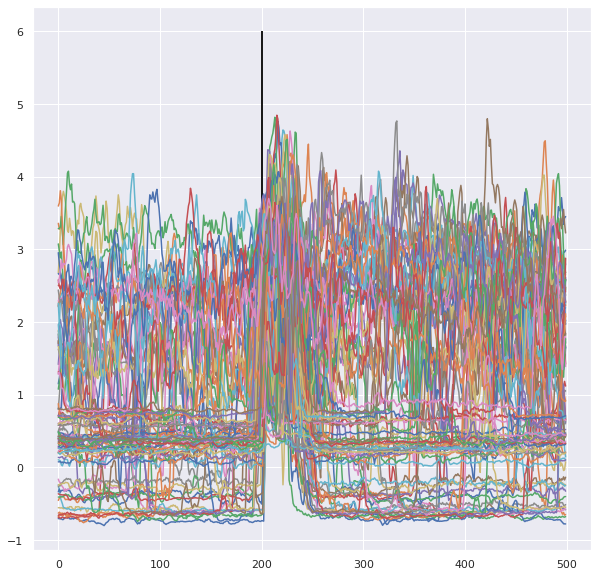

In [77]:
plt.figure(figsize=(10,10))
for i in range(M_body_pc.shape[1]):
    plt.plot(M_body_pc[:,i]+0.02*i)
plt.vlines(range(running_onset,running_onset+1),0, 6,linewidth = 2)
# plt.xlim([,680])

(180.0, 205.0)

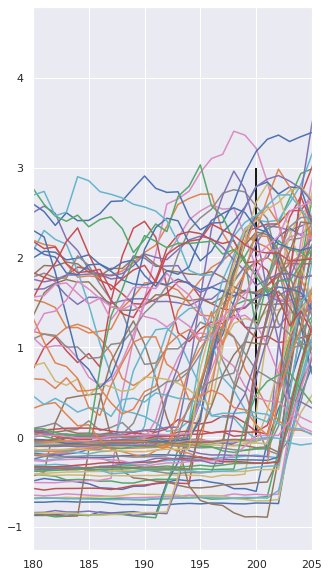

In [78]:
plt.figure(figsize=(5,10))
for i in range(M_rotf.shape[1]):
    plt.plot(M_body_pc[:,i]+0.01*i)
plt.vlines(range(running_onset,running_onset+1),0, 3,linewidth = 2)
plt.xlim([180,205])

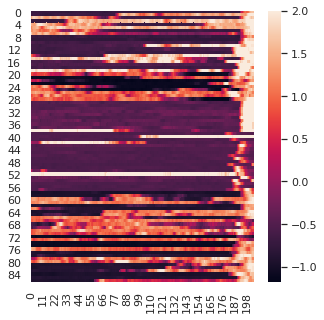

In [81]:
plt.figure(figsize=(5,5))
sns.heatmap(M_body_pc[10:215,:].T,vmax=2)

In [82]:
T_PRE_new = 185
running_onset = T_PRE_new

**first pass**

(41,)


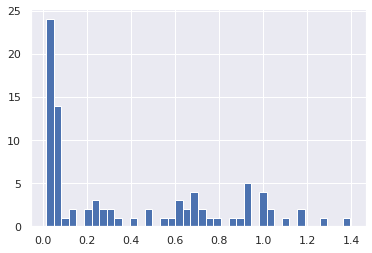

In [83]:
before_running_std = np.std(M_body_pc[:T_PRE_new-5,:],axis=0)
n, bins, patches = plt.hist(before_running_std,bins=40)
ss = 0.2
ss_ind = before_running_std<ss
print(np.where(ss_ind==True)[0].shape)

In [84]:
print('before ',M_rotf.shape)

M_rotf = M_rotf[:,ss_ind]
M_rotf_raw = M_rotf_raw[:,ss_ind]
M_face_pc = M_face_pc[:,ss_ind]
M_body_pc = M_body_pc[:,ss_ind]
M_day_label = M_day_label[ss_ind]
M_jrgeco = M_jrgeco[:,:,ss_ind]
M_jrgeco_std = M_jrgeco_std[:,:,ss_ind]
M_chbt = M_chbt[:,:,ss_ind]
M_chbt_std = M_chbt_std[:,:,ss_ind]
M_pupil_pc = M_pupil_pc[:,ss_ind]
M_whisk_vel = M_whisk_vel[:,ss_ind]
M_whisk_vel_norm = M_whisk_vel_norm[:,ss_ind]
M_nose_vel = M_nose_vel[:,ss_ind]
M_nose_vel_norm = M_nose_vel_norm[:,ss_ind]
M_pupil_p_value = M_pupil_p_value[:,ss_ind]

M_is_groom = M_is_groom[:,ss_ind]
M_y_rise_LFP_raw = M_y_rise_LFP_raw[:,ss_ind]
M_y_rise_LFP = M_y_rise_LFP[:,ss_ind]


M_LFP_vel=M_LFP_vel[:,ss_ind]
M_LFP_vel_norm=M_LFP_vel_norm[:,ss_ind]
M_RFP_vel=M_RFP_vel[:,ss_ind]
M_RFP_vel_norm=M_RFP_vel_norm[:,ss_ind]
M_pupil_pc_norm=M_pupil_pc_norm[:,ss_ind]

M_mirrorRFP_vel = M_mirrorRFP_vel[:,ss_ind]
M_mirrorRFP_vel_norm = M_mirrorRFP_vel_norm[:,ss_ind]
M_mirrorLFP_vel = M_mirrorLFP_vel[:,ss_ind]
M_mirrorLFP_vel_norm = M_mirrorLFP_vel_norm[:,ss_ind]
M_mirrorRHP_vel = M_mirrorRHP_vel[:,ss_ind]
M_mirrorRHP_vel_norm = M_mirrorRHP_vel_norm[:,ss_ind]
M_mirrorLHP_vel = M_mirrorLHP_vel[:,ss_ind]
M_mirrorLHP_vel_norm = M_mirrorLHP_vel_norm[:,ss_ind]

print('after ',M_mirrorLHP_vel_norm.shape)





before  (500, 87)
after  (500, 41)


(0.0, 280.0)

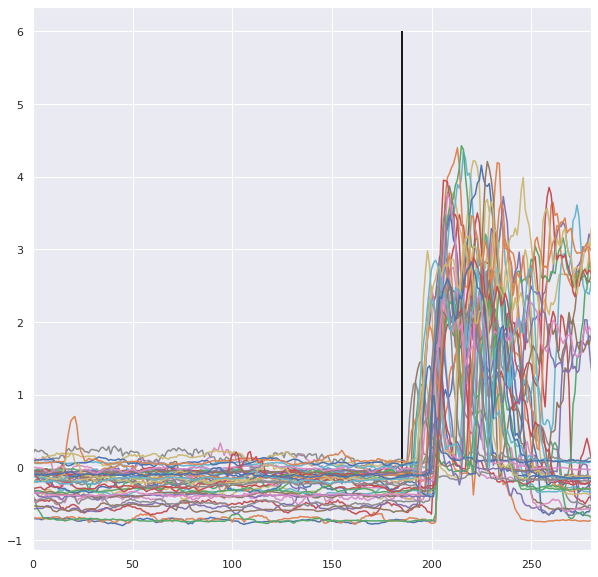

In [85]:
plt.figure(figsize=(10,10))
for i in range(M_body_pc.shape[1]):
    plt.plot(M_body_pc[:,i]+0.02*i)
plt.vlines(range(running_onset,running_onset+1),0, 6,linewidth = 2)
plt.xlim([0,280])

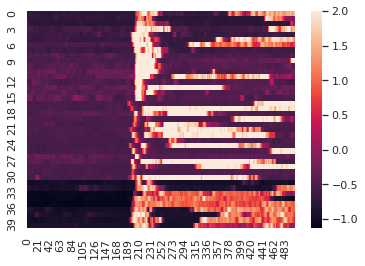

In [86]:
sns.heatmap(M_body_pc.T,vmax=2)

In [89]:
scipy.io.savemat('/home/wx2203/Weihao/analysis_locker/f2stim/'+mouse+'_filtered.mat',
                       {'M_jrgeco':M_jrgeco,
                        'M_jrgeco_std':M_jrgeco_std,
                        'M_chbt':M_chbt,
                        'M_chbt_std':M_chbt_std,
                        'M_rotf':M_rotf,
                        'M_rotf_raw':M_rotf_raw,
                        'M_face_pc':M_face_pc,
                        'M_body_pc':M_body_pc,
                       'M_pupil_pc':M_pupil_pc,
                        'M_whisk_vel':M_whisk_vel,
                        'M_whisk_vel_norm':M_whisk_vel_norm,
                        'M_nose_vel':M_nose_vel,
                        'M_nose_vel_norm':M_nose_vel_norm,
                        'M_pupil_p_value':M_pupil_p_value,
                        'M_LFP_vel':M_LFP_vel,
                        'M_LFP_vel_norm':M_LFP_vel_norm,
                        'M_RFP_vel':M_RFP_vel,
                        'M_RFP_vel_norm':M_RFP_vel_norm,
                        'M_pupil_pc_norm':M_pupil_pc_norm,
                       'M_day_label':M_day_label,
                        'M_is_groom':M_is_groom,
                       'M_ind_groom_onset':M_ind_groom_onset,
                       'M_y_rise_LFP':M_y_rise_LFP,
                       'M_y_rise_LFP_raw':M_y_rise_LFP_raw,
                      'M_mirrorRFP_vel':M_mirrorRFP_vel,
                       'M_mirrorRFP_vel_norm':M_mirrorRFP_vel_norm,
                        'M_mirrorLFP_vel':M_mirrorLFP_vel,
                        'M_mirrorLFP_vel_norm':M_mirrorLFP_vel_norm,
                        'M_mirrorRHP_vel':M_mirrorRHP_vel,
                        'M_mirrorRHP_vel_norm':M_mirrorRHP_vel_norm,
                        'M_mirrorLHP_vel':M_mirrorLHP_vel,
                        'M_mirrorLHP_vel_norm':M_mirrorLHP_vel_norm})




